# Actividad 1.2 · Aprendizaje no supervisado: PCA y K-means
**Maestría en Inteligencia Artificial · TecNM Virtual** — Aprendizaje Automático Avanzado, Unidad 1  
**Autores:** Arturo Pérez y María D. Camacho · **Fecha:** octubre de 2026 · **Versión del modelo:** v1.0  
[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/artperezg/AA_Actividad1.2_Paradigmas/blob/main/notebooks/02_no_supervisado_PCA_KMeans.ipynb)

**Caso de estudio:** segmentar a los clientes de un distribuidor mayorista según su gasto anual, sin usar etiquetas.

| Punto de la actividad (Tarea 4) | Sección |
|---|---|
| Caso distinto, dataset y definición de variables | 1 |
| Preparación de los datos | 2 |
| PCA: aplicación y función | 3 |
| K-means: aplicación y función | 4 |
| Identificación y descripción de agrupaciones | 5 |
| Métricas y resultados importantes | 6 |

In [1]:
# Configuración: en Colab descarga el proyecto desde GitHub (no requiere Google Drive)
import sys, warnings, zipfile
from pathlib import Path

REPO_URL = "https://github.com/artperezg/AA_Actividad1.2_Paradigmas.git"
EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    RAIZ = Path("/content/AA_Actividad1.2_Paradigmas")
    if not RAIZ.exists():
        import subprocess
        r = subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(RAIZ)], capture_output=True, text=True)
        if r.returncode != 0:
            raise RuntimeError("No se pudo descargar el repositorio:\n" + r.stderr)
else:
    RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_RAW, DATA_PROC = RAIZ / "data" / "raw", RAIZ / "data" / "processed"
DATA_PROC.mkdir(parents=True, exist_ok=True)
RESULTADOS = RAIZ / "resultados" / "02_no_supervisado"
MODELOS = RESULTADOS / "modelos"
MODELOS.mkdir(parents=True, exist_ok=True)
SEMILLA, VERSION_MODELO = 42, "v1.0"
print("Raíz del proyecto:", RAIZ)

Raíz del proyecto: /content/AA_Actividad1.2_Paradigmas


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

def guardar_figura(nombre):
    ruta = RESULTADOS / f"{nombre}.png"
    plt.savefig(ruta, dpi=150, bbox_inches="tight")
    print("Figura guardada:", ruta.relative_to(RAIZ))
COLORES_GRUPOS = ["#2a9d8f", "#e76f51"]

## 1. Dataset y variables
**Dataset:** *Wholesale customers*, UCI Machine Learning Repository, id 292 (Cardoso, 2014). Contiene 440 clientes de un distribuidor mayorista de Portugal. Es distinto al dataset de la parte supervisada.

| Variable | Descripción | Uso |
|---|---|---|
| `Fresh`, `Milk`, `Grocery`, `Frozen`, `Detergents_Paper`, `Delicassen` | Gasto anual (u.m.) en frescos, lácteos, abarrotes, congelados, detergentes y papel, y delicatessen | **Variables de agrupamiento** (6 características) |
| `Channel` | Canal: 1 = Horeca (hotel, restaurante, cafetería), 2 = minorista | **Variable objetivo**, solo para interpretar los grupos al final |
| `Region` | Región: 1 = Lisboa, 2 = Oporto, 3 = otra | No se usa |

In [3]:
if not (DATA_RAW / "Wholesale customers data.csv").exists():
    with zipfile.ZipFile(DATA_RAW / "wholesale_customers.zip") as z:
        z.extract("Wholesale customers data.csv", DATA_RAW)
df = pd.read_csv(DATA_RAW / "Wholesale customers data.csv")
VARIABLES = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]
NOMBRES = {"Fresh": "Frescos", "Milk": "Lácteos", "Grocery": "Abarrotes", "Frozen": "Congelados",
           "Detergents_Paper": "Detergentes y papel", "Delicassen": "Delicatessen"}
print(f"Clientes: {df.shape[0]} | Columnas: {df.shape[1]} | Faltantes: {int(df.isna().sum().sum())} | Duplicados: {df.duplicated().sum()}")
df.head()

Clientes: 440 | Columnas: 8 | Faltantes: 0 | Duplicados: 0


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


## 2. Preparación de los datos

| Paso | Técnica | Por qué |
|---|---|---|
| 1. Transformación | $\log(1 + x)$ | El gasto tiene asimetría extrema (unos cuantos clientes compran muchísimo) |
| 2. Limpieza de ruido | Se eliminan los clientes atípicos en **dos o más** variables (regla de Tukey) | Los centroides de K-means son promedios y se desplazan con valores extremos |
| 3. Estandarización | *z-score* | K-means usa distancia euclidiana y el PCA usa la covarianza |

In [4]:
X_log = np.log1p(df[VARIABLES])
display(pd.DataFrame({"asimetría original": df[VARIABLES].skew(), "asimetría con log": X_log.skew()}).round(2))

conteo = pd.Series(0, index=df.index)                    # en cuántas variables es atípico cada cliente
for var in VARIABLES:
    q1, q3 = X_log[var].quantile([0.25, 0.75]); ric = q3 - q1
    conteo += ((X_log[var] < q1 - 1.5 * ric) | (X_log[var] > q3 + 1.5 * ric)).astype(int)
ruido = conteo[conteo >= 2].index.tolist()
print("Clientes atípicos en dos o más variables (eliminados):", ruido)

df_limpio = df.drop(index=ruido)
escalador = StandardScaler().fit(np.log1p(df_limpio[VARIABLES]))
Z = escalador.transform(np.log1p(df_limpio[VARIABLES]))  # matriz final para PCA y K-means
print(f"Clientes para el análisis: {len(df_limpio)}")

df_limpio.to_csv(DATA_PROC / "wholesale_limpio.csv", index_label="id_cliente")
pd.DataFrame(Z, columns=VARIABLES, index=df_limpio.index).join(df_limpio[["Channel", "Region"]]) \
  .to_csv(DATA_PROC / "wholesale_transformado.csv", index_label="id_cliente")

,asimetría original,asimetría con log
Fresh,2.56,-1.58
Milk,4.05,-0.22
Grocery,3.59,-0.67
Frozen,5.91,-0.35
Detergents_Paper,3.63,-0.24
Delicassen,11.15,-1.09


Clientes atípicos en dos o más variables (eliminados): [65, 66, 75, 128, 154]
Clientes para el análisis: 435


## 3. PCA (análisis de componentes principales)
**Función en las pruebas:** encontrar las combinaciones de variables que concentran la mayor varianza de los datos. Así se resumen las 6 categorías de gasto en pocos ejes interpretables y se visualizan los clientes en un plano de 2 dimensiones.

Figura guardada: resultados/02_no_supervisado/01_pca.png


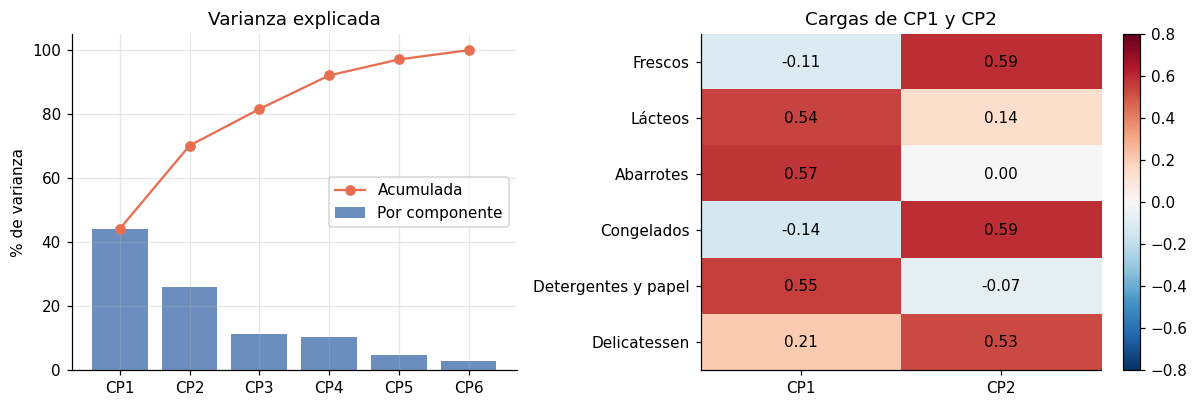

,CP1,CP2,CP3,CP4,CP5,CP6
% varianza,44.2,26.0,11.4,10.5,4.9,2.9
% acumulada,44.2,70.2,81.6,92.1,97.1,100.0


In [5]:
pca = PCA(random_state=SEMILLA).fit(Z)
varianza = pd.DataFrame({"% varianza": pca.explained_variance_ratio_ * 100,
                         "% acumulada": pca.explained_variance_ratio_.cumsum() * 100},
                        index=[f"CP{i + 1}" for i in range(6)]).round(1)
cargas = pd.DataFrame(pca.components_[:2].T, index=[NOMBRES[v] for v in VARIABLES], columns=["CP1", "CP2"]).round(2)
varianza.to_csv(RESULTADOS / "pca_varianza.csv"); cargas.to_csv(RESULTADOS / "pca_cargas.csv")

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8))
ejes[0].bar(varianza.index, varianza["% varianza"], color="#6c8ebf", label="Por componente")
ejes[0].plot(varianza.index, varianza["% acumulada"], "o-", color="#e76f51", label="Acumulada")
ejes[0].set_ylabel("% de varianza"); ejes[0].set_title("Varianza explicada"); ejes[0].legend(loc="center right")
im = ejes[1].imshow(cargas, cmap="RdBu_r", vmin=-0.8, vmax=0.8, aspect="auto")
ejes[1].set_xticks([0, 1], cargas.columns); ejes[1].set_yticks(range(6), cargas.index); ejes[1].grid(False)
for i in range(6):
    for j in range(2):
        ejes[1].text(j, i, f"{cargas.iloc[i, j]:.2f}", ha="center", va="center")
ejes[1].set_title("Cargas de CP1 y CP2"); plt.colorbar(im, ax=ejes[1], fraction=0.05)
plt.tight_layout()
guardar_figura("01_pca")
plt.show()
varianza.T

- CP1 y CP2 explican el **70.2 %** de la varianza (44.2 % y 26.0 %).
- **CP1, consumo de productos de tienda:** cargas altas en abarrotes (0.57), detergentes y papel (0.55) y lácteos (0.54).
- **CP2, consumo de perecederos:** cargas altas en frescos (0.59), congelados (0.59) y delicatessen (0.53).

## 4. K-means
**Función en las pruebas:** dividir a los clientes en $k$ grupos minimizando la **inercia** (suma de distancias cuadradas de cada cliente al centroide de su grupo). El número de grupos se elige con el **método del codo** y el **coeficiente de silueta** (de −1 a 1; más alto indica grupos más compactos y separados).

Figura guardada: resultados/02_no_supervisado/02_seleccion_k.png


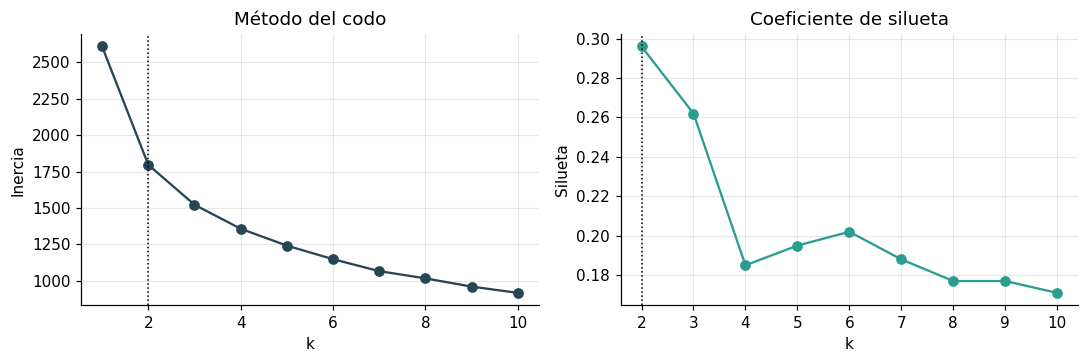

,inercia,silueta
k,,
1,2610.0,—
2,1797.29,0.296
3,1522.828,0.262
4,1357.906,0.185
5,1242.037,0.195
6,1148.797,0.202
7,1066.498,0.188
8,1017.0,0.177
9,960.331,0.177


In [6]:
filas = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(Z)
    filas.append({"k": k, "inercia": km.inertia_, "silueta": silhouette_score(Z, km.labels_) if k > 1 else np.nan})
seleccion = pd.DataFrame(filas).round(3)
seleccion.to_csv(RESULTADOS / "seleccion_k.csv", index=False)

fig, ejes = plt.subplots(1, 2, figsize=(10, 3.4))
ejes[0].plot(seleccion["k"], seleccion["inercia"], "o-", color="#264653"); ejes[0].set_title("Método del codo")
ejes[1].plot(seleccion["k"], seleccion["silueta"], "o-", color="#2a9d8f"); ejes[1].set_title("Coeficiente de silueta")
for ax, etiqueta in zip(ejes, ["Inercia", "Silueta"]):
    ax.set_xlabel("k"); ax.set_ylabel(etiqueta); ax.axvline(2, color="k", ls=":", lw=1)
plt.tight_layout()
guardar_figura("02_seleccion_k")
plt.show()
seleccion.set_index("k").astype(object).fillna("—")

**Se eligió k = 2.** La silueta es máxima con dos grupos (0.296, frente a 0.262 con k = 3), y el codo más marcado también está en k = 2: la inercia baja 31 % al pasar de 1 a 2 grupos y solo 15 % al pasar de 2 a 3.

## 5. Agrupaciones identificadas

Figura guardada: resultados/02_no_supervisado/03_grupos.png


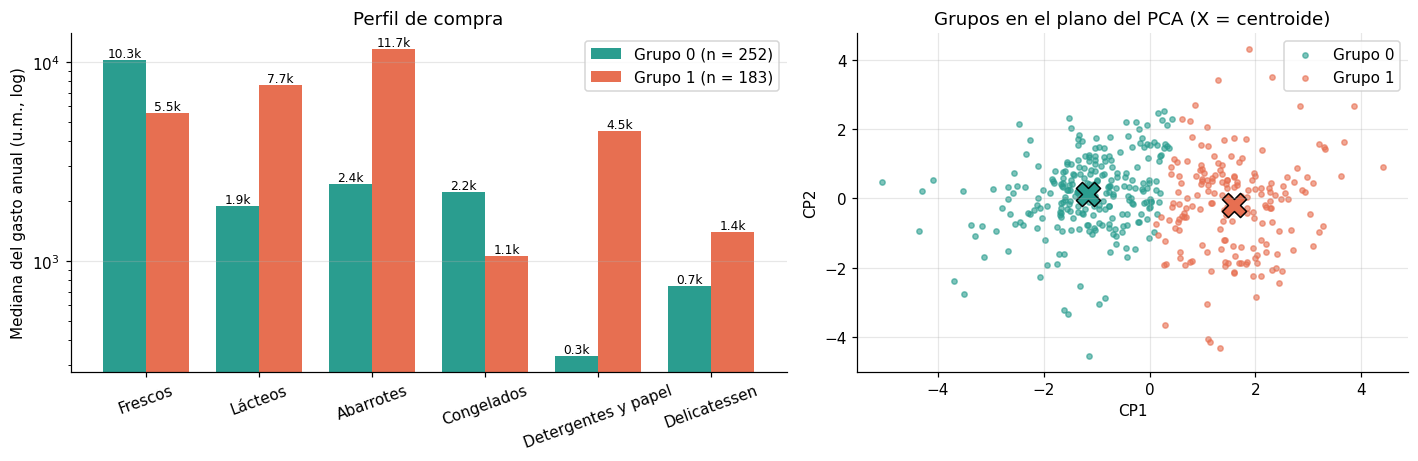

,Frescos,Lácteos,Abarrotes,Congelados,Detergentes y papel,Delicatessen,Clientes
Grupo 0,10271,1889,2442,2212,332,746,252
Grupo 1,5550,7704,11687,1066,4515,1393,183
Mediana general,8565,3634,4757,1541,813,967,435


In [7]:
km = KMeans(n_clusters=2, n_init=10, random_state=SEMILLA).fit(Z)
orden = np.argsort(km.cluster_centers_[:, VARIABLES.index("Grocery")])     # numeración estable: grupo 0 = menos abarrotes
kmeans_final = KMeans(n_clusters=2, init=km.cluster_centers_[orden], n_init=1).fit(Z)
grupos = kmeans_final.labels_

perfil = df_limpio[VARIABLES].groupby(grupos).median().rename(columns=NOMBRES)
perfil.index = [f"Grupo {g}" for g in perfil.index]
perfil["Clientes"] = np.bincount(grupos)
perfil.loc["Mediana general"] = list(df_limpio[VARIABLES].median()) + [len(df_limpio)]
perfil.astype(int).to_csv(RESULTADOS / "perfil_grupos.csv")

P = pca.transform(Z)
centros = pca.transform(kmeans_final.cluster_centers_)
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.3), gridspec_kw={"width_ratios": [1.3, 1]})
x = np.arange(6)
for g in range(2):
    medianas = df_limpio.loc[grupos == g, VARIABLES].median()
    barras = ejes[0].bar(x + (g - 0.5) * 0.38, medianas, 0.38, color=COLORES_GRUPOS[g], label=f"Grupo {g} (n = {(grupos == g).sum()})")
    ejes[0].bar_label(barras, labels=[f"{v / 1000:.1f}k" for v in medianas], fontsize=8)
    ejes[1].scatter(P[grupos == g, 0], P[grupos == g, 1], s=12, alpha=0.6, color=COLORES_GRUPOS[g], label=f"Grupo {g}")
    ejes[1].scatter(*centros[g, :2], s=250, marker="X", color=COLORES_GRUPOS[g], edgecolor="k")
ejes[0].set_yscale("log"); ejes[0].set_xticks(x, [NOMBRES[v] for v in VARIABLES], rotation=20)
ejes[0].set_ylabel("Mediana del gasto anual (u.m., log)"); ejes[0].set_title("Perfil de compra"); ejes[0].legend()
ejes[0].grid(axis="x", visible=False)
ejes[1].set_xlabel("CP1"); ejes[1].set_ylabel("CP2"); ejes[1].set_title("Grupos en el plano del PCA (X = centroide)"); ejes[1].legend()
plt.tight_layout()
guardar_figura("03_grupos")
plt.show()
perfil.astype(int)

| | **Grupo 0: perfil Horeca** | **Grupo 1: perfil minorista** |
|---|---|---|
| Clientes | 252 (58 %) | 183 (42 %) |
| Compra más que la mediana | Frescos y congelados | Abarrotes, lácteos, y detergentes y papel |
| Compra menos que la mediana | Detergentes y papel, abarrotes y lácteos | Frescos y congelados |
| Interpretación | Negocios que preparan alimentos (restaurantes, hoteles, cafeterías) | Comercios que revenden productos empacados |

## 6. Métricas y resultados
La variable `Channel` no se usó para entrenar; aquí solo sirve para comprobar si los grupos tienen significado. El **índice de Rand ajustado (ARI)** vale 1 si dos particiones coinciden por completo y ≈ 0 si coinciden al azar.

In [8]:
canal = df_limpio["Channel"].map({1: "Horeca", 2: "Minorista"})
print(f"Inercia: {kmeans_final.inertia_:.1f} | Silueta: {silhouette_score(Z, grupos):.3f} | "
      f"ARI con el canal: {adjusted_rand_score(df_limpio['Channel'], grupos):.3f}")

modelo_segmentacion = Pipeline([("log", FunctionTransformer(np.log1p)), ("escalamiento", StandardScaler()),
                                ("kmeans", KMeans(n_clusters=2, init=kmeans_final.cluster_centers_, n_init=1))]).fit(df_limpio[VARIABLES])
joblib.dump(modelo_segmentacion, MODELOS / f"kmeans_{VERSION_MODELO}.joblib")
joblib.dump(pca, MODELOS / f"pca_{VERSION_MODELO}.joblib")
df_limpio.assign(grupo=grupos).to_csv(RESULTADOS / "asignacion_clientes.csv", index_label="id_cliente")
pd.crosstab(pd.Series(grupos, index=df_limpio.index, name="Grupo"), canal, margins=True, margins_name="Total")

Inercia: 1797.3 | Silueta: 0.296 | ARI con el canal: 0.535


Channel,Horeca,Minorista,Total
Grupo,,,
0,244,8,252
1,50,133,183
Total,294,141,435


- **Silueta de 0.296:** los dos grupos existen, aunque con cierto traslape entre ellos.
- **Validación con el canal:** el 97 % del grupo 0 son clientes Horeca (244 de 252) y el 73 % del grupo 1 son minoristas (133 de 183). El ARI de 0.535 indica una coincidencia sustancial, sin haber usado la etiqueta para entrenar.

In [9]:
import sklearn, platform
print("Python", platform.python_version(), "| scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

Python 3.12.3 | scikit-learn 1.8.0 | pandas 3.0.2 | numpy 2.4.4
